# Walmart weekly sales analysis

Compare weekly sales across stores, summarize holiday and regular weeks, and check how sales co-vary with economic fields. This notebook adapts the repository’s [original Python script](walmartanalysis.py).

The saved charts use **fictional demonstration data** with the same column names as the original script. Set `INPUT_CSV` to your own store-week CSV to run the workflow with observed sales. The legacy CSV is absent from the repository.

## Load the store-week data

Each row represents one store and one weekly observation. Holiday flags use 1 for holiday and 0 for regular. Install `pandas`, `numpy`, and `matplotlib` before running.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import numpy as np
import pandas as pd

INPUT_CSV = None  # Example: Path("Walmart.csv")

if INPUT_CSV is None:
    rng = np.random.default_rng(27)
    weeks = pd.date_range("2023-01-06", periods=24, freq="W-FRI")
    store_ids = np.repeat([101, 102, 103, 104], len(weeks))
    week_index = np.tile(np.arange(len(weeks)), 4)
    holiday_flags = np.isin(week_index, [5, 13, 21]).astype(int)
    sales = 51_000 + (store_ids - 101) * 5_800 + holiday_flags * 4_700
    data = pd.DataFrame({
        "Store": store_ids,
        "Date": np.tile(weeks, 4),
        "Weekly_Sales": np.round(sales + rng.normal(0, 3_500, len(sales)), 2),
        "Holiday_Flag": holiday_flags,
        "Temperature": 43 + 1.4 * week_index + rng.normal(0, 3, len(sales)),
        "Fuel_Price": 2.75 + .027 * week_index + rng.normal(0, .06, len(sales)),
        "CPI": 208 + .15 * week_index + rng.normal(0, .07, len(sales)),
    })
    chart_context = "Fictional demonstration data"
else:
    data = pd.read_csv(Path(INPUT_CSV))
    chart_context = "Input CSV"


## Validate the grain and fields

The same week may appear across stores. Require one record per store-week and retain the counts behind each mean.

In [2]:
required = {"Store", "Date", "Weekly_Sales", "Holiday_Flag"}
missing_columns = required.difference(data.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

data = data.copy()
data["Date"] = pd.to_datetime(data["Date"], format="mixed", dayfirst=True, errors="coerce")
data["Weekly_Sales"] = pd.to_numeric(data["Weekly_Sales"], errors="coerce")
data["Holiday_Flag"] = pd.to_numeric(data["Holiday_Flag"], errors="coerce")
if data.empty or data[list(required)].isna().any().any():
    raise ValueError("Provide nonempty store-week rows with valid dates, sales, and holiday flags.")
if not np.isfinite(data["Weekly_Sales"]).all():
    raise ValueError("Weekly_Sales must contain finite values.")
if not data["Holiday_Flag"].isin([0, 1]).all():
    raise ValueError("Holiday_Flag must contain only 0 or 1.")
if data.duplicated(["Store", "Date"]).any():
    raise ValueError("The input has duplicate store-week records.")

data["Week type"] = data["Holiday_Flag"].map({0: "Regular", 1: "Holiday"})
period = f"{data['Date'].min():%b %Y} to {data['Date'].max():%b %Y}"
print(f"{chart_context} · {len(data):,} store-weeks · {data['Store'].nunique():,} stores · {period}")


Fictional demonstration data · 96 store-weeks · 4 stores · Jan 2023 to Jun 2023


## Compare stores

Average weekly sales can be compared across stores, subject to differences in the number and timing of observations.

,observations,average
Store,,
104,24,68754.20
103,24,63269.36
102,24,57549.67
101,24,50746.49


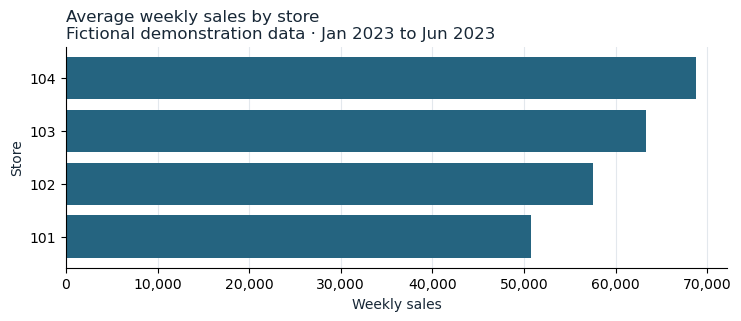

In [3]:
plot_style = {
    "figure.dpi": 100,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.grid": True,
    "axes.grid.axis": "x",
    "grid.color": "#e3e8ed",
    "text.color": "#172736",
    "axes.labelcolor": "#172736",
}
chart_subtitle = f"{chart_context} · {period}"
by_store = data.groupby("Store")["Weekly_Sales"].agg(
    observations="size", average="mean"
)
display(by_store.sort_values("average", ascending=False).head(10).round(2))

with plt.rc_context(plot_style):
    store_chart = by_store.nlargest(10, "average").sort_values("average")
    fig, ax = plt.subplots(figsize=(7.3, 3.1), layout="constrained")
    ax.barh(store_chart.index.astype(str), store_chart["average"], color="#256480")
    ax.set_title("Average weekly sales by store" + chr(10) + chart_subtitle, loc="left")
    ax.set_xlabel("Weekly sales")
    ax.set_ylabel("Store")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    plt.show()


## Compare holidays with regular weeks

Compare holiday and regular weeks within each store with observations for both categories. The grouped summary reports store-week counts and averages.

,observations,average
Week type,,
Holiday,12,64606.50
Regular,84,59433.28


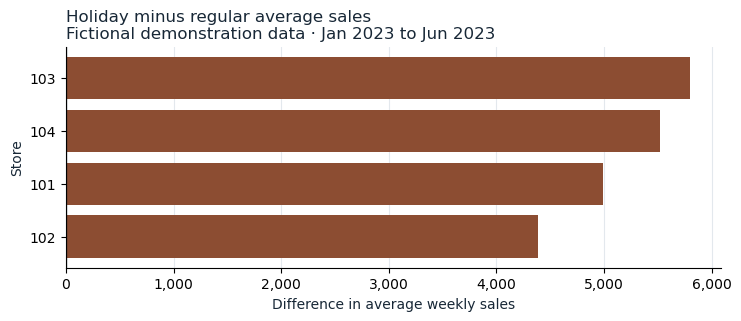

In [4]:
by_week_type = data.groupby("Week type")["Weekly_Sales"].agg(
    observations="size", average="mean"
)
display(by_week_type.round(2))

means = data.pivot_table(
    index="Store", columns="Week type", values="Weekly_Sales", aggfunc="mean"
).reindex(columns=["Regular", "Holiday"])
matched = means.dropna().copy()
matched["difference"] = matched["Holiday"] - matched["Regular"]

if matched.empty:
    print("A within-store holiday comparison needs both holiday and regular observations.")
else:
    chart = matched["difference"].loc[
        matched["difference"].abs().nlargest(10).index
    ].sort_values()
    with plt.rc_context(plot_style):
        fig, ax = plt.subplots(figsize=(7.3, 3.1), layout="constrained")
        ax.barh(chart.index.astype(str), chart, color="#8c4d32")
        ax.axvline(0, color="#172736", linewidth=.9)
        ax.set_title("Holiday minus regular average sales" + chr(10) + chart_subtitle, loc="left")
        ax.set_xlabel("Difference in average weekly sales")
        ax.set_ylabel("Store")
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        plt.show()


## Check economic fields

Pearson correlations describe linear associations in the supplied rows. Common timing and store-level effects can influence the numbers.

In [5]:
economic_fields = [name for name in ("Temperature", "Fuel_Price", "CPI") if name in data]
if economic_fields:
    numeric = data[economic_fields].apply(pd.to_numeric, errors="coerce")
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    correlations = numeric.corrwith(data["Weekly_Sales"])
    display(pd.DataFrame({"Pairs": numeric.count(), "Pearson r": correlations}).round(3))
else:
    print("Optional economic fields are absent from the input.")


,Pairs,Pearson r
Temperature,96,-0.023
Fuel_Price,96,-0.034
CPI,96,-0.039


## Reading the results

The example’s store baselines and holiday effect were assigned when generating fictional data. With an observed CSV, compare observation counts and coverage first. The charts and correlations describe associations in those store-week rows. A causal estimate would need a design that addresses differences by store and date.